# Support Vector Machine

In [ ]:
'''
- Does both regression and classification tasks.
- SVR and SVC
- It requires small set datasets.
- Model Parameters
    kernel = (linear, rbf(default), poly)
            - rbf -> Radial Basis Function
    C = (0.01, 0.1, 1.0, 10, 100)
    gamma = (0.01, 0.1, 1.0, scale, 10)

- Stratify
'''

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import SVM Model
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
df = pd.read_csv('Dataset/Cardiovascular_Disease.csv')
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [3]:
df['age'] = df['age'] // 363

In [4]:
filtered_df = df[
    (df['height'].between(150, 190)) &
    (df['weight'].between(45, 110)) &
    (df['ap_hi'].between(90, 180)) &
    (df['ap_lo'].between(50, 90))
]

In [5]:
df_sample = filtered_df.sample(n=6000, random_state=42)

In [6]:
df_sample.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

## Feature and Target

In [7]:
features = ['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 
            'gluc', 'smoke', 'alco', 'active']
target = 'cardio'

In [9]:
X = df_sample[features]
Y = df_sample[target]

## Train and Test Data

In [10]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

## Feature Scaling

In [11]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

## Model Implementation

In [12]:
model = SVC(
    kernel='linear',
    C = 1.0,
    gamma= 'scale'
)
model.fit(X_train_scale, Y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [13]:
Y_pred = model.predict(X_test_scale)
Y_pred

array([1, 0, 0, ..., 0, 1, 0], shape=(1200,))

In [14]:
cm = confusion_matrix(Y_test, Y_pred)
cr = classification_report(Y_test, Y_pred)

In [15]:
print(cm)

[[541 106]
 [223 330]]


In [16]:
print(cr)

              precision    recall  f1-score   support

           0       0.71      0.84      0.77       647
           1       0.76      0.60      0.67       553

    accuracy                           0.73      1200
   macro avg       0.73      0.72      0.72      1200
weighted avg       0.73      0.73      0.72      1200



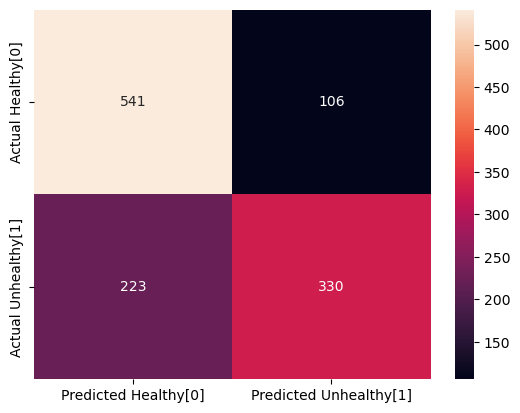

In [17]:
sns.heatmap(cm, annot=True, fmt='1.0f', xticklabels=['Predicted Healthy[0]', 'Predicted Unhealthy[1]'],
           yticklabels=['Actual Healthy[0]', 'Actual Unhealthy[1]'])
plt.show()

## New Data Prediction

In [18]:
data = {
    'age': [30, 45, 39], 
    'gender': [1, 2, 1], 
    'height': [151, 160, 157], 
    'weight': [60, 70, 50], 
    'ap_hi': [120, 140, 160], 
    'ap_lo': [90, 80, 60], 
    'cholesterol': [1, 3, 2], 
    'gluc': [1, 1, 2], 
    'smoke': [0, 1, 1], 
    'alco': [1, 1, 1], 
    'active': [0, 1, 0]
}

In [19]:
input_data = pd.DataFrame(data)
input_data

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active
0,30,1,151,60,120,90,1,1,0,1,0
1,45,2,160,70,140,80,3,1,1,1,1
2,39,1,157,50,160,60,2,2,1,1,0


In [20]:
input_scale = scaler.transform(input_data)
pred = model.predict(input_scale)
input_data['cardio_pred'] = pred

In [21]:
input_data

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio_pred
0,30,1,151,60,120,90,1,1,0,1,0,0
1,45,2,160,70,140,80,3,1,1,1,1,1
2,39,1,157,50,160,60,2,2,1,1,0,1
